# N161 · H1 control with skip, quarter rate, and nominal rate

Each arm gets 15,232 decisions in each of two BDD streams, 30,464 total. The
N160 video order, 128-frame observation window, warm learner, and nominal-rate
and quarter-rate full-admission baselines carry over. Completed baseline clips
can be restored from N160 when the identical inputs and state are verified.

At each arrival forecast the immediate health after skip, 1/4 LR, or nominal
LR. Among eligible rates, minimize predicted/current image loss plus 0.5 times
current/predicted RankMe. Every positive rate must forecast improvement on both
metrics. The four guard variants use a rate-specific offline median floor on
loss, RankMe, both, or neither. A nonpositive median uses the strictly positive
fallback. Configurations with identical guards share a deterministic trajectory.

Fresh H1 trials fork the same learner and AdamW state at each origin and measure
skip, quarter-rate, and nominal-rate outcomes on the same origin assay. The
three original N158 clip-disjoint splits provide separate fitting, calibration
and offline testing. The reference paths use a fixed schedule over the new
rates. The predictor learns online from measured effects of executed updates.

The simple next-arrival H1 forecaster learns separately on each metric. Actual
loss, contextual RankMe, and independent audit health have their own trajectories.
Forecast RMSE compares with persistence on the same observations. Exact training
loss is retained for every accepted frame. The clip pools are reused development
data and the source change is the action set and its paired offline calibration.


## Live status

**complete** · All H1 quarter and nominal comparisons saved

Updated UTC `2026-11-06T19:43:54+00:00` · PID `40028`.

All 121,856 physical decisions are complete.

Free disk **17.5 GiB** with a 3 GiB reserve.

## Offline gain floors

| Rate | Measured loss median | Measured RankMe median | Loss floor | RankMe floor |
|---|---:|---:|---:|---:|
| 0.25 | +0.000509 | -0.000899 | 0.000509 | 0.000000 |
| 1 | +0.001971 | -0.003691 | 0.001971 | 0.000000 |

**RankMe only** shares the **Neither** trajectory because their floors match at both rates.

**Both** shares the **Loss only** trajectory because their floors match at both rates.

## Coverage and actual measurements

| Stream / arm | Decisions | Updates | Current loss | Contextual RankMe | Actual trained loss | Scene probe |
|---|---:|---:|---:|---:|---:|---:|
| pool_1/full_admission | 15,232 | 15,232 | 0.78534 | 1.19100 | 0.77030 | 41.89% |
| pool_1/quarter_admission | 15,232 | 15,232 | 0.79488 | 1.51785 | 0.77578 | 41.22% |
| pool_1/mpc_neither | 15,232 | 1,874 | 0.87712 | 1.59983 | 0.83360 | 40.94% |
| pool_1/mpc_loss | 15,232 | 2,083 | 0.88977 | 1.61855 | 0.86087 | 40.44% |
| pool_2/full_admission | 15,232 | 15,232 | 0.82131 | 1.27766 | 0.80445 | 44.56% |
| pool_2/quarter_admission | 15,232 | 15,232 | 0.83104 | 1.57302 | 0.81085 | 42.67% |
| pool_2/mpc_neither | 15,232 | 1,696 | 0.89220 | 1.57973 | 0.91015 | 38.56% |
| pool_2/mpc_loss | 15,232 | 715 | 0.91243 | 1.59063 | 0.92872 | 40.50% |

## Forecast / persistence RMSE

| Stream / arm | Forecast | Observations | Loss | RankMe | Variance | Actual guard misses |
|---|---|---:|---:|---:|---:|---:|
| pool_1/full_admission | Next arrival | 15,231 | 0.042971 / 0.043337 | 0.022567 / 0.022538 | 0.0096361 / 0.009633 | — |
| pool_1/quarter_admission | Next arrival | 15,231 | 0.035449 / 0.035696 | 0.042893 / 0.042914 | 0.012921 / 0.012927 | — |
| pool_1/mpc_neither | Next arrival | 15,231 | 0.046352 / 0.047234 | 0.044182 / 0.044212 | 0.015002 / 0.015011 | — |
| pool_1/mpc_neither | Action H1 | 1,874 | 0.0041334 / 0.005037 | 0.0054439 / 0.0057535 | 0.0048726 / 0.0051775 | 1107 |
| pool_1/mpc_loss | Next arrival | 15,231 | 0.033725 / 0.033972 | 0.045395 / 0.045421 | 0.012202 / 0.012211 | — |
| pool_1/mpc_loss | Action H1 | 2,083 | 0.0050133 / 0.0064803 | 0.008365 / 0.0088351 | 0.0047509 / 0.0048485 | 1214 |
| pool_2/full_admission | Next arrival | 15,231 | 0.039693 / 0.040059 | 0.031668 / 0.031689 | 0.01081 / 0.010814 | — |
| pool_2/quarter_admission | Next arrival | 15,231 | 0.034969 / 0.035243 | 0.044239 / 0.044293 | 0.015364 / 0.015374 | — |
| pool_2/mpc_neither | Next arrival | 15,231 | 0.024765 / 0.02499 | 0.04741 / 0.047502 | 0.018957 / 0.01898 | — |
| pool_2/mpc_neither | Action H1 | 1,696 | 0.0048278 / 0.006224 | 0.01802 / 0.018176 | 0.010839 / 0.011155 | 1076 |
| pool_2/mpc_loss | Next arrival | 15,231 | 0.022059 / 0.022244 | 0.047321 / 0.047394 | 0.014618 / 0.014634 | — |
| pool_2/mpc_loss | Action H1 | 715 | 0.0068285 / 0.0095275 | 0.01462 / 0.014759 | 0.012369 / 0.013595 | 543 |

## Final equal-pool results

| Configuration | Incoming loss | Final audit loss | Final audit RankMe | Scene accuracy | Updates |
|---|---:|---:|---:|---:|---:|
| Nominal | 0.803326 | 1.224018 | 1.98724 | 43.22% | 30,464 |
| Quarter rate | 0.812959 | 1.038652 | 2.55335 | 41.94% | 30,464 |
| Neither | 0.884662 | 0.941408 | 2.51751 | 39.75% | 3,570 |
| Loss only | 0.901099 | 0.958339 | 3.00372 | 40.47% | 2,798 |
| RankMe only | 0.884662 | 0.941408 | 2.51751 | 39.75% | 3,570 |
| Both | 0.901099 | 0.958339 | 3.00372 | 40.47% | 2,798 |

## Offline H1 forecast / persistence RMSE

106 held-out origins, paired positive rates.

| Current loss | Bank loss | RankMe | Variance |
|---:|---:|---:|---:|
| 0.0048301 / 0.0045438 | 0.0017454 / 0.0020241 | 0.0079633 / 0.0077666 | 0.0041783 / 0.004152 |

### Actual loss and RankMe over time

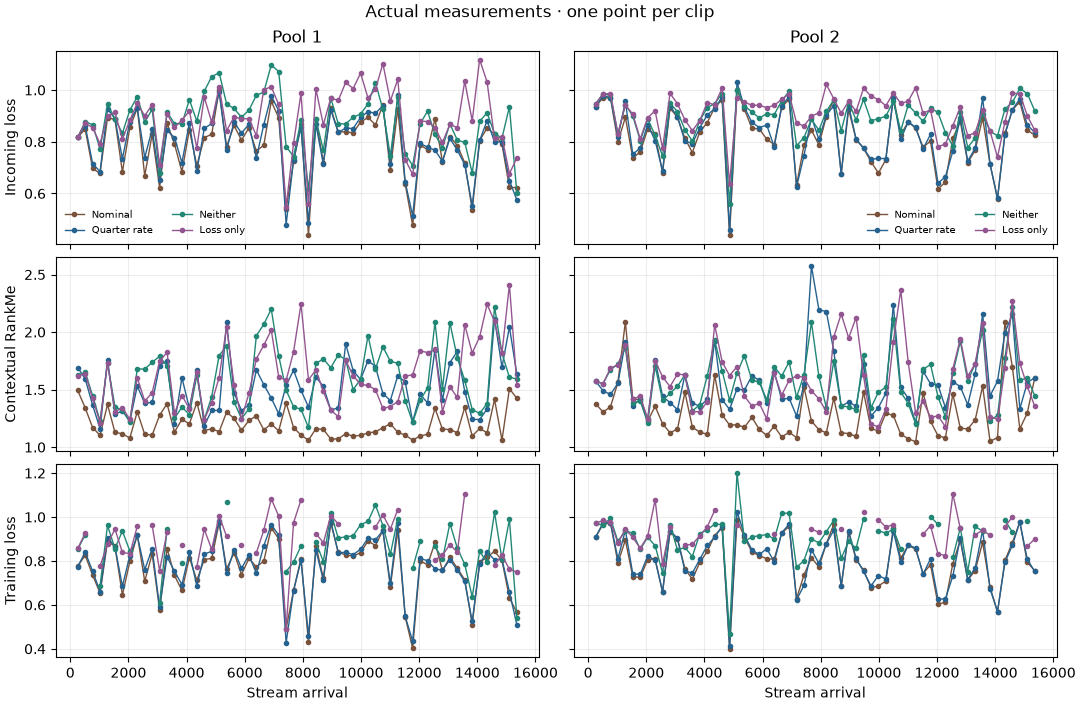

### Independent audit health

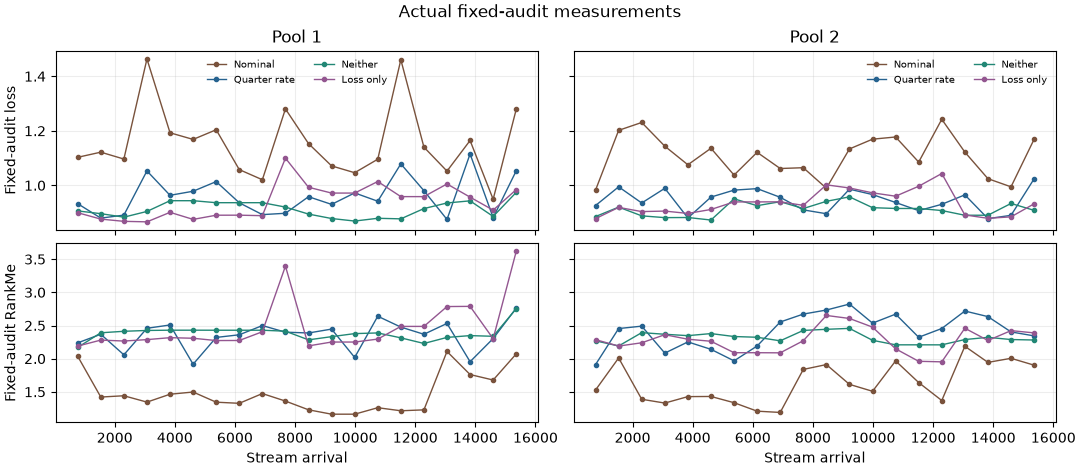

### Next-arrival H1 forecast RMSE

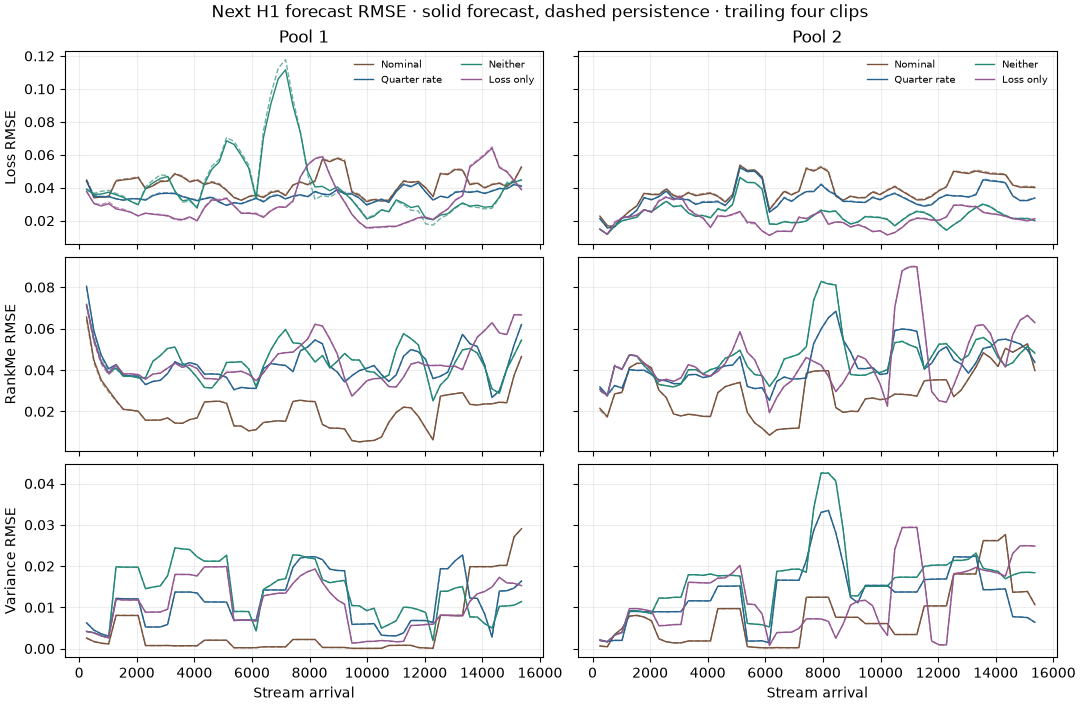

### Action H1 forecast RMSE

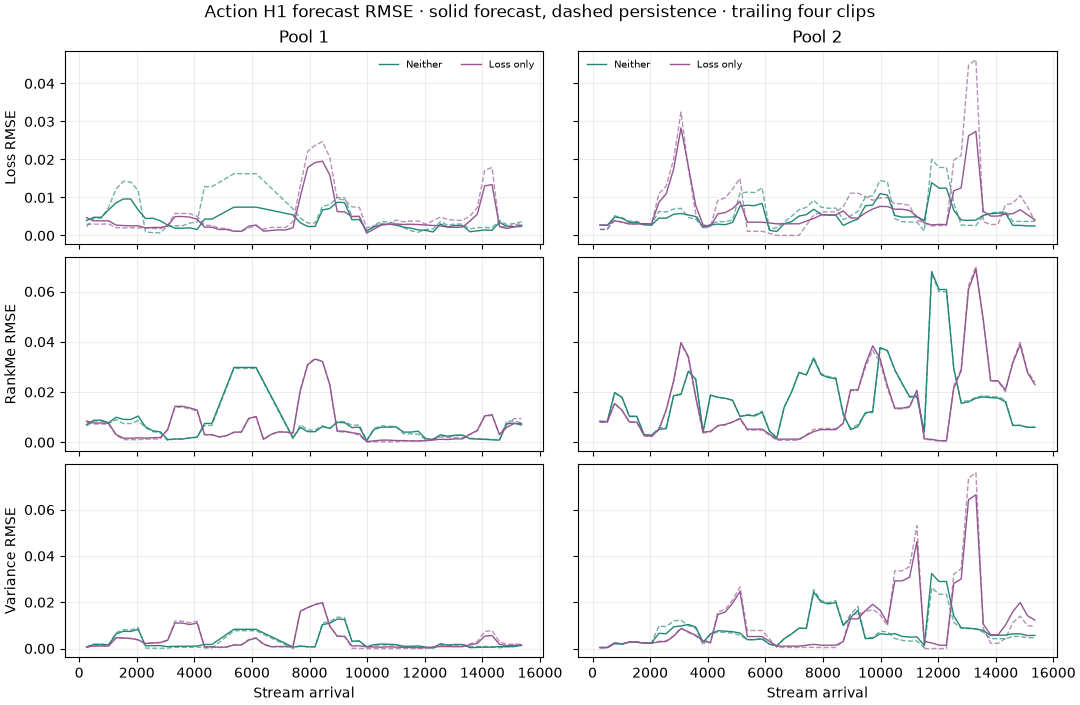